# M6.3 · 自适应执行算法

> 固定拆单无法适应盘中成交量变化。自适应执行根据实时成交量与参与率反馈动态调整每笔数量，
> 并实时累计 TCA、处理拒单与超时。

## 一、机制

1. **自适应 POV**：按目标参与率跟随市场成交量，实际参与率偏高时自动减速；
2. **订单管理**：拒单按退避重试、超时判定，超过重试上限则放弃；
3. **实时 TCA**：执行中累计成交量、加权均价与相对到达价滑点。

## 二、自适应 POV 与执行管理

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab2 import adaptive_exec as ae
pov = ae.AdaptivePOV(total_qty=1000, target_pov=0.1)
mkt_vols = [2000, 3000, 4000, 5000]
slices = [pov.next_slice(v) for v in mkt_vols]
print('POV slices=%s 剩余=%.0f 完成=%s' % (slices, pov.remaining, pov.done()))
pov2 = ae.AdaptivePOV(1000, 0.1)
print('超参与率减速后 slice=%.2f' % pov2.next_slice(3000, realized_pov=0.2))
om = ae.OrderManager(max_retry=2, timeout_s=10); om.submit('o1', {'id': 'o1'})
om.on_reject('o1'); om.on_reject('o1'); om.on_reject('o1')
print('三次拒单后状态=%s' % om.orders['o1']['status'])
tca = ae.RealtimeTCA(arrival_px=10.0)
tca.update(10.02, 500); snap = tca.update(10.05, 500)
print('实时TCA: 成交=%d 均价=%.3f 滑点=%.1fbps' % (snap['filled'], snap['avg_px'], snap['slippage_bps']))

POV slices=[200.0, 300.0, 400.0, 100.0] 剩余=0 完成=True
超参与率减速后 slice=150.00
三次拒单后状态=DEAD
实时TCA: 成交=1000 均价=10.035 滑点=35.0bps


## 三、可视化

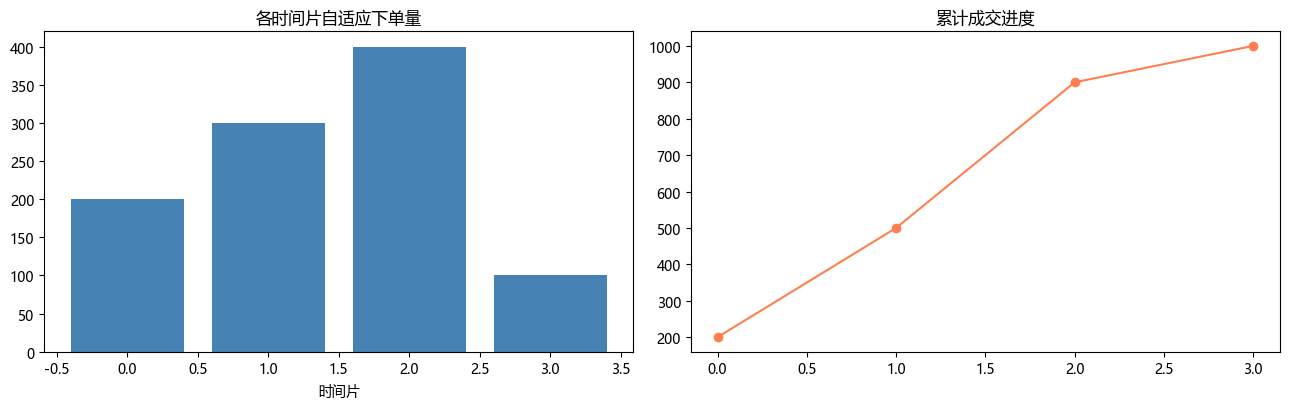

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(range(len(slices)), slices, color='steelblue')
ax[0].set_title('各时间片自适应下单量'); ax[0].set_xlabel('时间片')
cum_qty = np.cumsum(slices)
ax[1].plot(cum_qty, color='coral', marker='o'); ax[1].set_title('累计成交进度')
plt.tight_layout(); plt.show()

## 四、面试要点

- **自适应相比固定 TWAP 的优势？** 跟随实时流动性，在成交量大时多执行、参与率偏高时减速，降低冲击与机会成本。
- **参与率反馈如何控制冲击？** 实时比较实际与目标参与率，偏离即下调后续 slice，避免集中交易。
- **拒单/超时如何处理？** 按退避重试，超过上限标记 DEAD 并报警，超时单撤单重报，保证订单状态可控。
- **实时 TCA 看什么？** 执行中累计均价相对到达价的滑点，及时发现执行偏差异常。

## 五、练习

1. 实现自适应 TWAP 并与 POV 对比。
2. 加入指数退避重试。
3. 用实时 TCA 触发中途切换算法。
4. 估计给定时限下的最优参与率。